# Учёт банковских операций

Модель счетов находится в `bank.py`. Ниже проверка правил задания: история и график, расчётный и сберегательный счета, перевод, загрузка `transactions_dirty.csv` и `transactions_dirty.json`.

## Задание 1. Счёт и история

Счёт открывается с именем владельца. Номер `ACC-1000` выдаётся автоматически, следующий счёт получает следующий номер. Снятие больше остатка оставляет баланс прежним и записывается в историю со статусом `fail`.

In [1]:
%matplotlib inline

from datetime import datetime, timedelta
from pathlib import Path

import pandas as pd

from bank import CheckingAccount, SavingsAccount

pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.max_rows", 40)

ROOT = Path.cwd()
CSV_PATH = ROOT / "transactions_dirty.csv"
JSON_PATH = ROOT / "transactions_dirty.json"
if not CSV_PATH.exists() or not JSON_PATH.exists():
    raise FileNotFoundError(
        "Запустите ноутбук из папки с transactions_dirty.csv "
        "и transactions_dirty.json"
    )

account = CheckingAccount("Мария Соколова")
opened = datetime(2026, 3, 1, 10, 0)
account.deposit(5_000, when=opened)
account.deposit(1_500, when=opened + timedelta(days=1))
account.withdraw(2_000, when=opened + timedelta(days=2))
failed = account.withdraw(8_000, when=opened + timedelta(days=3))

print(account)
print()
print(f"Статус снятия 8000: {failed.status}")
print(f"Баланс: {account.balance:.2f}")
assert failed.status == "fail"
assert account.balance == 4_500
account.to_dataframe()

Счёт ACC-1000 (расчётный), владелец: Мария Соколова, баланс: 4500.00
История:
  2026-03-01 10:00:00  deposit          5000.00  success  баланс    5000.00
  2026-03-02 10:00:00  deposit          1500.00  success  баланс    6500.00
  2026-03-03 10:00:00  withdraw         2000.00  success  баланс    4500.00
  2026-03-04 10:00:00  withdraw         8000.00  fail     баланс    4500.00

Статус снятия 8000: fail
Баланс: 4500.00


,операция,сумма,дата,баланс после операции,статус,перевод
0,deposit,5000.00,2026-03-01 10:00:00,5000.00,success,
1,deposit,1500.00,2026-03-02 10:00:00,6500.00,success,
2,withdraw,2000.00,2026-03-03 10:00:00,4500.00,success,
3,withdraw,8000.00,2026-03-04 10:00:00,4500.00,fail,


## График баланса

По оси X - время операции, по оси Y - баланс после операции. Точки берутся из истории через pandas. Последняя точка - отклонённое снятие: баланс остался прежним.

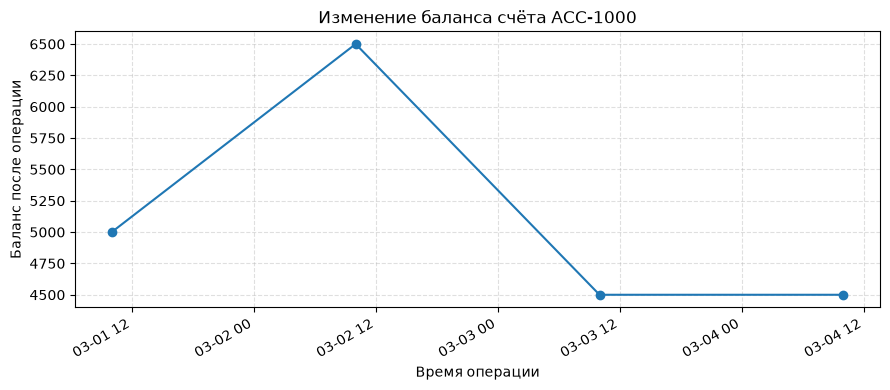

In [2]:
account.plot_balance();

## Задание 2. Расчётный и сберегательный счета

У расчётного счёта снятие ограничено остатком. Сберегательный начисляет проценты: доля `0.07` — это 7%. С него нельзя снять больше половины текущего остатка. После начисления на 10000 баланс равен 10700, половина — 5350.

In [3]:
checking = CheckingAccount("Пётр Иванов", 15_000)
savings = SavingsAccount("Анна Кузнецова", 10_000)
moment = datetime(2026, 4, 1, 12, 0)

print(repr(checking))
print(repr(savings))

checking.deposit(1_000, when=moment)
savings.apply_interest(0.07, when=moment + timedelta(days=1))
print(f"После начисления 7%: {savings.balance:.2f}")

over_limit = savings.withdraw(5_351, when=moment + timedelta(days=2))
print(f"Снятие 5351: {over_limit.status}, баланс {savings.balance:.2f}")

allowed = savings.withdraw(5_350, when=moment + timedelta(days=3))
print(f"Снятие 5350: {allowed.status}, баланс {savings.balance:.2f}")

savings.deposit(4_000, when=moment + timedelta(days=4))
savings.deposit(2_500, when=moment + timedelta(days=5))
savings.deposit(1_500, when=moment + timedelta(days=6))
print()
print(savings)

assert checking.account_type == "checking"
assert savings.account_type == "savings"
assert over_limit.status == "fail"
assert allowed.status == "success"
assert savings.balance == 13_350
assert checking.balance == 16_000

CheckingAccount(number='ACC-1001', owner='Пётр Иванов', balance=15000.00)
SavingsAccount(number='ACC-1002', owner='Анна Кузнецова', balance=10000.00)
После начисления 7%: 10700.00
Снятие 5351: fail, баланс 10700.00
Снятие 5350: success, баланс 5350.00

Счёт ACC-1002 (сберегательный), владелец: Анна Кузнецова, баланс: 13350.00
История:
  2026-04-02 12:00:00  interest          700.00  success  баланс   10700.00
  2026-04-03 12:00:00  withdraw         5351.00  fail     баланс   10700.00
  2026-04-04 12:00:00  withdraw         5350.00  success  баланс    5350.00
  2026-04-05 12:00:00  deposit          4000.00  success  баланс    9350.00
  2026-04-06 12:00:00  deposit          2500.00  success  баланс   11850.00
  2026-04-07 12:00:00  deposit          1500.00  success  баланс   13350.00


## Крупные операции

Последние 3 успешные операции с суммой от 1000. Начисление 700 ниже порога и в выборку не входит.

In [4]:
print("Последние 3 успешные операции с суммой от 1000:")
selected = savings.large_operations(3, 1_000)
assert list(selected["сумма"]) == [4_000, 2_500, 1_500]
selected

Последние 3 успешные операции с суммой от 1000:


,операция,сумма,дата,баланс после операции,статус,перевод
0,deposit,4000.00,2026-04-05 12:00:00,9350.00,success,
1,deposit,2500.00,2026-04-06 12:00:00,11850.00,success,
2,deposit,1500.00,2026-04-07 12:00:00,13350.00,success,


## Проверка имени и суммы

Имя должно быть в формате "Имя Фамилия": два слова с заглавной буквы, кириллица или латиница. Проверка сделана регулярным выражением. Некорректные имя, начальный баланс и сумма операции завершаются исключением.

In [5]:
invalid_names = (
    "иван петров",
    "Ivan",
    "Анна",
    "Maria sokolova",
)
for name in invalid_names:
    try:
        CheckingAccount(name)
    except ValueError as error:
        print(f"{name!r}: {error}")

try:
    CheckingAccount("Иван Петров", -500)
except ValueError as error:
    print(f"Начальный баланс -500: {error}")

try:
    checking.deposit(0)
except ValueError as error:
    print(f"Сумма 0: {error}")

try:
    checking.withdraw(-20)
except ValueError as error:
    print(f"Сумма -20: {error}")

latin = CheckingAccount("Maria Sokolova", 100)
print(f"{latin.number}: {latin.owner}, баланс {latin.balance:.2f}")
assert checking.balance == 16_000

'иван петров': Имя владельца должно быть в формате «Имя Фамилия»: два слова с заглавной буквы, кириллица или латиница
'Ivan': Имя владельца должно быть в формате «Имя Фамилия»: два слова с заглавной буквы, кириллица или латиница
'Анна': Имя владельца должно быть в формате «Имя Фамилия»: два слова с заглавной буквы, кириллица или латиница
'Maria sokolova': Имя владельца должно быть в формате «Имя Фамилия»: два слова с заглавной буквы, кириллица или латиница
Начальный баланс -500: Начальный баланс не может быть отрицательным
Сумма 0: Сумма операции должна быть положительной
Сумма -20: Сумма операции должна быть положительной
ACC-1003: Maria Sokolova, баланс 100.00


## Перевод между счетами

Успешные записи отправителя и получателя связаны общим идентификатором. Сберегательный счёт отдаёт не больше 50% остатка. При отказе баланс получателя сохраняется, а в истории отправителя остаётся `transfer_out` со статусом `fail`.

In [6]:
sent = checking.transfer_to(
    savings,
    2_000,
    when=datetime(2026, 6, 1, 9, 0),
)
print(f"Перевод {sent.transfer_id}: {sent.status}")
print(f"Расчётный: {checking.balance:.2f}")
print(f"Сберегательный: {savings.balance:.2f}")

denied = savings.transfer_to(
    checking,
    8_000,
    when=datetime(2026, 6, 2, 9, 0),
)
print(f"Перевод {denied.transfer_id}: {denied.status}")
print(f"Расчётный: {checking.balance:.2f}")
print(f"Сберегательный: {savings.balance:.2f}")

back = savings.transfer_to(
    checking,
    7_000,
    when=datetime(2026, 6, 3, 9, 0),
)
print(f"Перевод {back.transfer_id}: {back.status}")
print(f"Расчётный: {checking.balance:.2f}")
print(f"Сберегательный: {savings.balance:.2f}")

assert sent.status == "success"
assert denied.status == "fail"
assert back.status == "success"
assert checking.balance == 21_000
assert savings.balance == 8_350

print()
print("Операции перевода на расчётном счёте:")
checking_history = checking.to_dataframe()
checking_history[checking_history["перевод"] != ""]

Перевод TR-0001: success
Расчётный: 14000.00
Сберегательный: 15350.00
Перевод TR-0002: fail
Расчётный: 14000.00
Сберегательный: 15350.00
Перевод TR-0003: success
Расчётный: 21000.00
Сберегательный: 8350.00

Операции перевода на расчётном счёте:


,операция,сумма,дата,баланс после операции,статус,перевод
1,transfer_out,2000.00,2026-06-01 09:00:00,14000.00,success,TR-0001
2,transfer_in,7000.00,2026-06-03 09:00:00,21000.00,success,TR-0003


In [7]:
print("Операции перевода на сберегательном счёте:")
savings_history = savings.to_dataframe()
savings_history[savings_history["перевод"] != ""]

Операции перевода на сберегательном счёте:


,операция,сумма,дата,баланс после операции,статус,перевод
6,transfer_in,2000.00,2026-06-01 09:00:00,15350.00,success,TR-0001
7,transfer_out,8000.00,2026-06-02 09:00:00,15350.00,fail,TR-0002
8,transfer_out,7000.00,2026-06-03 09:00:00,8350.00,success,TR-0003


## Задание 3. Грязные данные

В файле операции нескольких счетов. В счёт попадают строки выбранного номера. Отбрасываются пустая и отрицательная сумма, битая дата, опечатка в типе (`diposit`, `wdraw`), пустой тип, статус `succes` и операция `interest` на расчётном счёте.

Остаток считается заново по принятым строкам в порядке файла. Поле `balance_after` в расчёт не входит. Повтор валидной строки в конце файла проводится ещё раз. Снятие, которое не проходит правила счёта на уже посчитанном остатке, тоже попадает в отчёт и баланс не меняет.

In [8]:
checking_loaded = CheckingAccount("Олег Морозов")
checking_report = checking_loaded.load_transactions(
    CSV_PATH,
    "ACC-100001",
)
print(checking_report)

Файл: transactions_dirty.csv
Счёт: ACC-1004
Номер в файле: ACC-100001
Строк в файле: 105
Отобрано по номеру: 26
Принято: 18
Отклонено: 8
Причины отклонения:
  недопустимый тип операции для счёта: interest: 2
  некорректная дата: 2
  некорректный статус: succes: 1
  опечатка в типе операции: diposit: 1
  пустая сумма: 1
  пустой тип операции: 1


In [9]:
checking_report.summary()

,причина,количество
0,недопустимый тип операции для счёта: interest,2
1,некорректная дата,2
2,некорректный статус: succes,1
3,опечатка в типе операции: diposit,1
4,пустая сумма,1
5,пустой тип операции,1


In [10]:
checking_report.details()

,строка,причина,операция,сумма,дата,статус,тип счёта
0,6,пустая сумма,withdraw,,2025-09-29 22:17:26,success,checking
1,9,пустой тип операции,,654.0,2025-10-01 22:17:26,success,checking
2,11,недопустимый тип операции для счёта: interest,interest,532.0,2025-10-03 22:17:26,success,checking
3,14,некорректная дата,deposit,793.0,2025-17-34 12:00:00,success,checking
4,16,опечатка в типе операции: diposit,diposit,669.0,2025-10-06 22:17:26,success,checking
5,17,недопустимый тип операции для счёта: interest,interest,744.0,2025-10-08 22:17:26,success,checking
6,18,некорректная дата,withdraw,111.0,2023-16-40 12:00:00,success,checking
7,25,некорректный статус: succes,deposit,916.0,2025-10-19 22:17:26,succes,checking


In [11]:
print(f"Баланс расчётного счёта: {checking_loaded.balance:.2f}")
checking_loaded.to_dataframe()

Баланс расчётного счёта: 3271.00


,операция,сумма,дата,баланс после операции,статус,перевод
0,deposit,921.00,2025-09-27 22:17:26,921.00,success,
1,deposit,607.00,2025-09-27 22:17:26,1528.00,success,
2,deposit,488.00,2025-09-28 22:17:26,2016.00,success,
3,deposit,129.00,2025-09-28 22:17:00,2145.00,success,
4,deposit,880.00,2025-09-29 22:17:26,3025.00,success,
5,withdraw,352.00,2025-10-01 22:17:26,2673.00,success,
6,withdraw,65.00,2025-10-01 22:17:26,2608.00,success,
7,withdraw,245.00,2025-10-01 22:17:26,2363.00,success,
8,deposit,327.00,2025-10-05 22:17:26,2690.00,success,
9,withdraw,333.00,2025-10-06 22:17:26,2357.00,success,


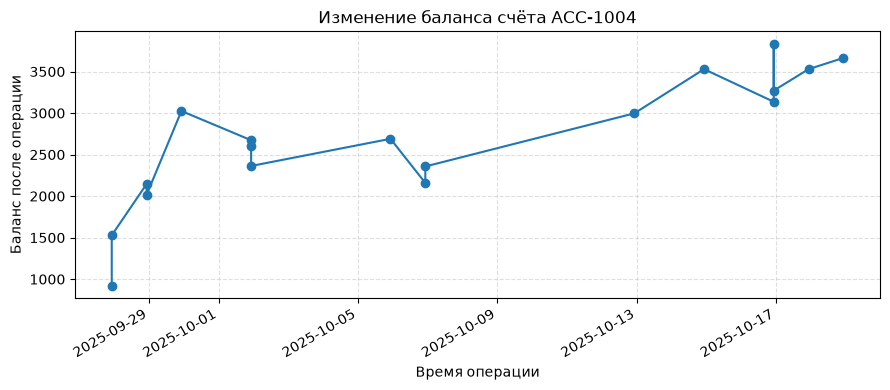

In [12]:
checking_loaded.plot_balance();

In [13]:
savings_loaded = SavingsAccount("Елена Волкова")
savings_report = savings_loaded.load_transactions(
    JSON_PATH,
    "ACC-100002",
)
print(savings_report)

Файл: transactions_dirty.json
Счёт: ACC-1005
Номер в файле: ACC-100002
Строк в файле: 105
Отобрано по номеру: 27
Принято: 18
Отклонено: 9
Причины отклонения:
  некорректный статус: succes: 2
  отрицательная сумма: 2
  некорректная дата: 1
  опечатка в типе операции: diposit: 1
  опечатка в типе операции: wdraw: 1
  превышен лимит снятия 50%: 1
  пустая сумма: 1


In [14]:
savings_report.summary()

,причина,количество
0,некорректный статус: succes,2
1,отрицательная сумма,2
2,некорректная дата,1
3,опечатка в типе операции: diposit,1
4,опечатка в типе операции: wdraw,1
5,превышен лимит снятия 50%,1
6,пустая сумма,1


In [15]:
savings_report.details()

,строка,причина,операция,сумма,дата,статус,тип счёта
0,27,превышен лимит снятия 50%,withdraw,392.0,2025-09-27 22:17:26,success,savings
1,29,некорректная дата,deposit,797.0,2023-22-32 12:00:00,success,savings
2,30,пустая сумма,interest,,2025-09-30 22:17:26,success,savings
3,34,отрицательная сумма,deposit,-136.0,2025-10-08 22:17:26,success,savings
4,38,опечатка в типе операции: diposit,diposit,432.0,2025-10-09 22:17:26,success,savings
5,45,отрицательная сумма,deposit,-872.0,2025-10-16 22:17:26,success,savings
6,47,некорректный статус: succes,withdraw,300.0,2025-10-19 22:17:26,succes,savings
7,49,опечатка в типе операции: wdraw,wdraw,457.0,2025-10-22 22:17:26,success,savings
8,104,некорректный статус: succes,withdraw,300.0,2025-10-19 22:17:26,succes,savings


In [16]:
print(f"Баланс сберегательного счёта: {savings_loaded.balance:.2f}")
savings_loaded.to_dataframe()

Баланс сберегательного счёта: 3521.24


,операция,сумма,дата,баланс после операции,статус,перевод
0,deposit,469.00,2025-09-27 22:17:26,469.00,success,
1,deposit,317.00,2025-09-28 22:17:26,786.00,success,
2,deposit,840.00,2025-10-02 22:17:26,1626.00,success,
3,interest,183.28,2025-10-04 22:17:00,1809.28,success,
4,interest,192.44,2025-10-06 22:17:26,2001.72,success,
5,deposit,426.00,2025-10-08 22:17:26,2427.72,success,
6,deposit,638.00,2025-10-09 22:17:00,3065.72,success,
7,withdraw,170.00,2025-10-09 22:17:26,2895.72,success,
8,deposit,622.00,2025-10-09 22:17:26,3517.72,success,
9,interest,306.26,2025-10-10 22:17:26,3823.98,success,


## Сверка CSV и JSON

Те же номера читаются из второго формата. Истории и балансы совпадают.

In [17]:
checking_from_json = CheckingAccount("Олег Морозов")
savings_from_csv = SavingsAccount("Елена Волкова")
checking_from_json.load_transactions(JSON_PATH, "ACC-100001")
savings_from_csv.load_transactions(CSV_PATH, "ACC-100002")

same_checking = checking_loaded.to_dataframe().equals(
    checking_from_json.to_dataframe()
)
same_savings = savings_loaded.to_dataframe().equals(
    savings_from_csv.to_dataframe()
)
assert same_checking and same_savings
print("CSV и JSON дали одну и ту же историю.")
print(f"Расчётный ACC-100001: {checking_loaded.balance:.2f}")
print(f"Сберегательный ACC-100002: {savings_loaded.balance:.2f}")

CSV и JSON дали одну и ту же историю.
Расчётный ACC-100001: 3271.00
Сберегательный ACC-100002: 3521.24
